<font size="12">**CNN-based image scene classification**

**Brazilian Coffee Scenes Dataset**

This dataset is a composition of scenes taken by SPOT sensor in 2005 over four counties in the State of Minas Gerais, Brazil: Arceburgo, Guaranesia,  Guaxupé and Monte Santo. It has many intraclass variance caused by different crop management techniques. Also, coffee is an evergreen culture and the South of Minas Gerais is a mountainous region, which means that this dataset includes scenes with different plant ages and/or with spectral distortions caused by shadows.

Please, cite this dataset as:  

*O. A. B. Penatti, K. Nogueira, J. A. dos Santos. Do Deep Features Generalize from Everyday Objects to Remote Sensing and Aerial Scenes Domains? In: EarthVision 2015, Boston. IEEE Computer Vision and Pattern Recognition Workshops, 2015.*

**Statistics**  

The whole image set of each country was partitioned into multiple tiles of 64 x 64 pixels. The identification of coffee crops (i.e. ground-truth annotation) was performed manually by agricultural researches. The dataset has:   

| Type | Tile | 
| --- | --- | 
| non-coffee (less than 10% of coffee pixels) | 35.577  | 
| coffee (at least 85% of coffee pixels) | 1.438  |



4 folds have 600 images each and the 5th has 476 images, all folds are balanced with coffee and non-coffee samples (50% each).


In [23]:
import tensorflow as tf
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Conv2D, MaxPool2D, LayerNormalization
from tensorflow.keras.layers import Flatten, Dropout
import numpy as np
from PIL import Image
from numpy import asarray

import pathlib

DATA_PATH = pathlib.Path().cwd() / "data"

# **Get the tiled image datasets, read and make list of the tiles read**

In [4]:
def get_images_from_txt(labels_txt_file, images_folder_path):
    output_list = []
    fold_labels_txt = open(labels_txt_file)
    
    for photo_label in fold_labels_txt:
        # split a label and a name
        is_coffee, photo_name = photo_label.strip().split('.', 1)
    
        photo_path = images_folder_path / f'{photo_name}.jpg'
    
        # convert image to numpy array
        image = Image.open(photo_path)
        image_as_array = asarray(image)
    
        output_list.append([is_coffee, photo_name, image_as_array])

    fold_labels_txt.close()
    
    return output_list
    
fold1_labels_txt = DATA_PATH / 'fold1.txt' 
fold2_labels_txt = DATA_PATH / 'fold2.txt'
fold3_labels_txt = DATA_PATH / 'fold3.txt'
fold4_labels_txt = DATA_PATH / 'fold4.txt'
fold1_path = DATA_PATH / 'fold1/'
fold2_path = DATA_PATH / 'fold2/'
fold3_path = DATA_PATH / 'fold3/'
fold4_path = DATA_PATH / 'fold4/'


label_photos = get_images_from_txt(fold1_labels_txt, fold1_path)
label_photos += get_images_from_txt(fold2_labels_txt, fold2_path)
label_photos += get_images_from_txt(fold3_labels_txt, fold3_path)
label_photos += get_images_from_txt(fold4_labels_txt, fold4_path)

#print(label_photos[0])

**Display some example images and lables**

In [5]:
import os

def find_file_in_subfolder(root, filename):
    # returns a full path to file from the root
    for file_root, dirs, files in os.walk(root):
        for name in files:
            if name == filename:
                return file_root + '/' + name

Image index and file:   1996 /Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/brazilian_coffee_scenes/fold4/guaxupe.T2240.B2304.L4544.R4608.jpg


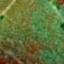

Image lable:   coffee
Image index and file:   2262 /Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/brazilian_coffee_scenes/fold4/guaranesia.T5696.B5760.L4864.R4928.jpg


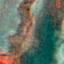

Image lable:   noncoffee
Image index and file:   1775 /Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/brazilian_coffee_scenes/fold3/arceburgo.T576.B640.L4480.R4544.jpg


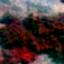

Image lable:   noncoffee
Image index and file:   2223 /Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/brazilian_coffee_scenes/fold4/montesanto.T8896.B8960.L4928.R4992.jpg


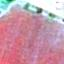

Image lable:   noncoffee
Image index and file:   143 /Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/brazilian_coffee_scenes/fold1/guaxupe.T1152.B1216.L3392.R3456.jpg


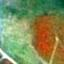

Image lable:   coffee


In [7]:
import random
for k in range(5):
    ind=random.randint(1,len(label_photos))
    img_path = find_file_in_subfolder(str(DATA_PATH), label_photos[ind][1] + '.jpg')
    print('Image index and file:  ', ind, img_path)
    img = Image.open(img_path)
    
    display(img)
    print('Image lable:  ',label_photos[ind][0])

In [8]:
print(len(label_photos[0])),label_photos[0]

3


(None,
 ['coffee',
  'montesanto.T3456.B3520.L2560.R2624',
  array([[[  0,   2,   0],
          [  5,   7,   0],
          [  6,   0,   0],
          ...,
          [ 58, 131, 242],
          [ 59, 131, 242],
          [ 67, 137, 249]],
  
         [[  6,   8,   0],
          [  1,   1,   0],
          [ 17,  13,   2],
          ...,
          [ 63, 139, 249],
          [ 62, 134, 245],
          [ 65, 137, 248]],
  
         [[  1,   1,   0],
          [  2,   2,   0],
          [  1,   0,   0],
          ...,
          [ 62, 140, 251],
          [ 64, 137, 250],
          [ 69, 142, 255]],
  
         ...,
  
         [[ 45, 126, 182],
          [ 43, 122, 178],
          [ 45, 122, 176],
          ...,
          [121, 104,  96],
          [122, 109, 101],
          [122, 112, 103]],
  
         [[ 53, 132, 188],
          [ 49, 128, 184],
          [ 53, 129, 181],
          ...,
          [115, 100,  93],
          [115, 104,  98],
          [115, 106,  99]],
  
         [[ 52, 131

**Normalize the data**

max_pixel_value = np.array(255)
for label_photo in label_photos:
    label_photo[-1] = label_photo[-1] / max_pixel_value

# **Data splitting**

In [9]:
import random
from sklearn.model_selection import train_test_split

random.shuffle(label_photos)
train_ds, test_ds = train_test_split(label_photos, test_size=0.3)

train_ds_labels = [True if photo_lb[0] == 'coffee' else False for photo_lb in train_ds]
train_ds_photos = [photo_lb[2] for photo_lb in train_ds]

test_ds_labels = [True if photo_lb[0] == 'coffee' else False for photo_lb in test_ds]
test_ds_photos = [photo_lb[2] for photo_lb in test_ds]

train_ds_labels = np.array(train_ds_labels)
train_ds_photos = np.array(train_ds_photos)
test_ds_labels = np.array(test_ds_labels)
test_ds_photos = np.array(test_ds_photos)

print(train_ds_labels[:10])
print(len(train_ds_photos))
print(len(test_ds_labels))
print(train_ds_photos[0].shape)

[ True False False  True  True False False False  True  True]
1680
720
(64, 64, 3)


**Define the model**

In [10]:
model = tf.keras.Sequential([
    Conv2D(96, kernel_size=(5, 5), activation='relu', input_shape=(64,64,3)),
    MaxPool2D(pool_size=(2, 2)),
    LayerNormalization(axis=[1, 2, 3]),
    Conv2D(256, kernel_size=(5, 5), activation='relu'),
    MaxPool2D(pool_size=(2, 2)),
    LayerNormalization(axis=[1, 2, 3]),
    Conv2D(256, kernel_size=(2, 2), activation='relu'),
    MaxPool2D(pool_size=(2, 2)),
    Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    Dropout(0.3),
    tf.keras.layers.Dense(512, activation='relu'),
    Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

/Users/simenkrogstie/Documents/Programming/H26/GMFM350/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Model summary**

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 60, 60, 96)     │         7,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 30, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 30, 30, 96)     │       172,800 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 13, 13, 256)    │        86,528 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 256)    │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,125,953 (23.37 MB)

 Trainable params: 6,125,953 (23.37 MB)

 Non-trainable params: 0 (0.00 B)

**Model compilation**

In [12]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

**Model training**

In [13]:
history = model.fit(train_ds_photos, train_ds_labels, epochs=100)

Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 176ms/step - accuracy: 0.5810 - loss: 0.9102
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 171ms/step - accuracy: 0.6690 - loss: 0.6111
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 180ms/step - accuracy: 0.7423 - loss: 0.5424
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.7607 - loss: 0.5422
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 167ms/step - accuracy: 0.7685 - loss: 0.5042
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.7738 - loss: 0.4966
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 174ms/step - accuracy: 0.7899 - loss: 0.4655
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.7935 - loss: 0.4402
Epoch 9/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 171ms/step - accuracy: 0.7881 - loss: 0.4508
Epoch 10/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 180ms/step - accuracy: 0.8060 - loss: 0.4225
Epoch 11/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 187ms/step - accuracy: 0.8137 - loss: 0.4057
Epoch 12/100
53/53 ━━━━━━━━━━━━━━━━━━

**Model evaluation.**

In [14]:

test_loss, test_acc = model.evaluate(test_ds_photos, test_ds_labels, verbose=2)

print('\nTest accuracy:', test_acc)

23/23 - 1s - 53ms/step - accuracy: 0.7944 - loss: 2.2497

Test accuracy: 0.7944444417953491


**Visualization of the training parameters**

/var/folders/t9/z7ntnjlj50q8tsg9qqq5lxgc0000gn/T/ipykernel_81343/3701259316.py:8: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  plt.plot(epochs, accuracy_per_epoch, 'b', color='Red', label='Training acc')


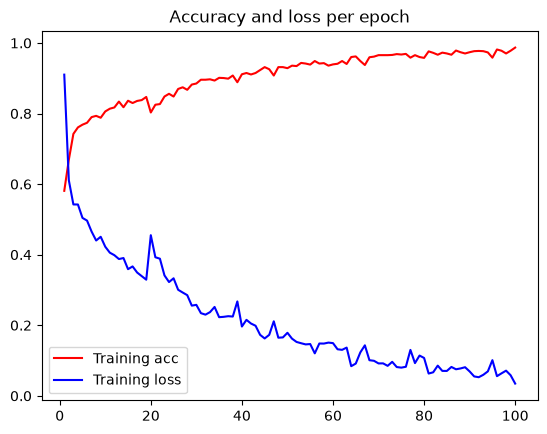

In [15]:
import matplotlib.pyplot as plt

accuracy_per_epoch = history.history['accuracy']
loss_per_epoch = history.history['loss']

epochs = range(1, len(loss_per_epoch) + 1)

plt.plot(epochs, accuracy_per_epoch, 'b', color='Red', label='Training acc')
plt.plot(epochs, loss_per_epoch, 'b', label='Training loss')
plt.title('Accuracy and loss per epoch')
plt.legend()
plt.show()

# **Using validation set during training**

**Split the dataset into three**

In [16]:
# Split the indices
n_train=np.int16(len(label_photos)*0.7)
n_val=np.int16(len(label_photos)*0.15)
#n_train=np.int(len(label_photos)*0.6)
print(n_train,n_val)

train_ds, val_ds,test_ds = np.split(np.array(range(len(label_photos))), [n_train, n_train + n_val])
train_ds=[label_photos[ind] for ind in train_ds]
val_ds=[label_photos[ind] for ind in val_ds]
test_ds=[label_photos[ind] for ind in test_ds]
#y_train, y_val, y_test = np.split(y, [n_train, n_train + n_val])

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

1680 360
Train: 1680, Val: 360, Test: 360


In [17]:

train_ds_labels = [True if photo_lb[0] == 'coffee' else False for photo_lb in train_ds]
train_ds_photos = [photo_lb[2] for photo_lb in train_ds]

test_ds_labels = [True if photo_lb[0] == 'coffee' else False for photo_lb in test_ds]
test_ds_photos = [photo_lb[2] for photo_lb in test_ds]


val_ds_labels = [True if photo_lb[0] == 'coffee' else False for photo_lb in val_ds]
val_ds_photos = [photo_lb[2] for photo_lb in val_ds]

train_ds_labels = np.array(train_ds_labels)
train_ds_photos = np.array(train_ds_photos)

test_ds_labels = np.array(test_ds_labels)
test_ds_photos = np.array(test_ds_photos)

val_ds_labels = np.array(val_ds_labels)
val_ds_photos = np.array(val_ds_photos)

print(train_ds_labels[:10])
print(len(train_ds_photos))
print(len(test_ds_labels))
print(len(val_ds_labels))
print(len(test_ds_photos[0].shape))

[False False  True False  True False  True  True False False]
1680
360
360
3


**Compile the model as a new**

In [18]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

**Train the model with validation set included**

In [20]:
history = model.fit(train_ds_photos, train_ds_labels,validation_data=[val_ds_photos,val_ds_labels], epochs=100)

Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 179ms/step - accuracy: 0.8524 - loss: 0.4616 - val_accuracy: 0.8611 - val_loss: 0.4343
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 191ms/step - accuracy: 0.8851 - loss: 0.2803 - val_accuracy: 0.8861 - val_loss: 0.4274
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 184ms/step - accuracy: 0.9125 - loss: 0.2386 - val_accuracy: 0.9167 - val_loss: 0.4219
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 10s 188ms/step - accuracy: 0.9280 - loss: 0.1946 - val_accuracy: 0.9250 - val_loss: 0.4223
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 179ms/step - accuracy: 0.9369 - loss: 0.1705 - val_accuracy: 0.9250 - val_loss: 0.3948
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.9429 - loss: 0.1619 - val_accuracy: 0.9000 - val_loss: 0.3506
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.9512 - loss: 0.1208 - val_accuracy: 0.9222 - val_loss: 0.3968
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 9s 177ms/step - accuracy: 0.9417 - loss: 0.1651 - val_

**Visualize the new training parameters.**

/var/folders/t9/z7ntnjlj50q8tsg9qqq5lxgc0000gn/T/ipykernel_81343/2657231204.py:8: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  plt.plot(epochs, history.history['accuracy'], 'b', color='Red', label='Training acc')


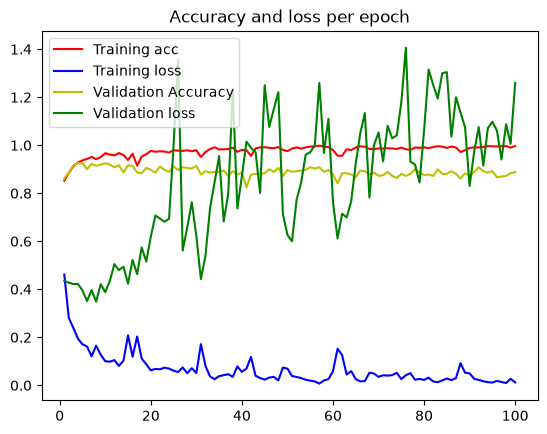

In [21]:
import matplotlib.pyplot as plt

accuracy_per_epoch = history.history['accuracy']
loss_per_epoch = history.history['loss']

epochs = range(1, len(loss_per_epoch) + 1)

plt.plot(epochs, history.history['accuracy'], 'b', color='Red', label='Training acc')
plt.plot(epochs, history.history['loss'], 'b', label='Training loss')
plt.plot(epochs, history.history['val_accuracy'], 'y', label='Validation Accuracy')
plt.plot(epochs, history.history['val_loss'], 'g', label='Validation loss')
plt.title('Accuracy and loss per epoch')
plt.legend()
plt.show()

**Deploying the trained model for coffee crop detection.**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Image: guaranesia.T4160.B4224.L3648.R3712
Is coffee: coffee
Model predicted: coffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/guaranesia.T4160.B4224.L3648.R3712.jpg


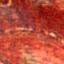

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Image: guaranesia.T8896.B8960.L5184.R5248
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 99.20999908447266%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold4/guaranesia.T8896.B8960.L5184.R5248.jpg


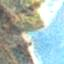

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: montesanto.T8960.B9024.L5568.R5632
Is coffee: coffee
Model predicted: coffee
Confidence: 99.98999786376953%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/montesanto.T8960.B9024.L5568.R5632.jpg


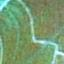

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: montesanto.T4224.B4288.L13056.R13120
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/montesanto.T4224.B4288.L13056.R13120.jpg


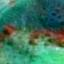

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: guaranesia.T3008.B3072.L5568.R5632
Is coffee: coffee
Model predicted: coffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold3/guaranesia.T3008.B3072.L5568.R5632.jpg


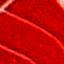

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Image: montesanto.T5376.B5440.L2944.R3008
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 50.97999954223633%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold3/montesanto.T5376.B5440.L2944.R3008.jpg


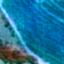

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: montesanto.T8384.B8448.L3904.R3968
Is coffee: coffee
Model predicted: coffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/montesanto.T8384.B8448.L3904.R3968.jpg


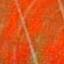

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: montesanto.T960.B1024.L9472.R9536
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/montesanto.T960.B1024.L9472.R9536.jpg


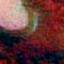

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Image: guaxupe.T8000.B8064.L1024.R1088
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold2/guaxupe.T8000.B8064.L1024.R1088.jpg


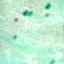

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Image: guaxupe.T4864.B4928.L3648.R3712
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/guaxupe.T4864.B4928.L3648.R3712.jpg


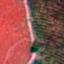

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Image: guaxupe.T3520.B3584.L3392.R3456
Is coffee: coffee
Model predicted: coffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold2/guaxupe.T3520.B3584.L3392.R3456.jpg


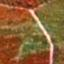

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Image: montesanto.T4288.B4352.L832.R896
Is coffee: coffee
Model predicted: coffee
Confidence: 99.98999786376953%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold4/montesanto.T4288.B4352.L832.R896.jpg


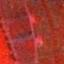

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: guaxupe.T7488.B7552.L5504.R5568
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/guaxupe.T7488.B7552.L5504.R5568.jpg


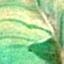

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: guaranesia.T6016.B6080.L4096.R4160
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 99.91000366210938%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold3/guaranesia.T6016.B6080.L4096.R4160.jpg


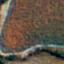

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Image: montesanto.T7744.B7808.L10176.R10240
Is coffee: coffee
Model predicted: noncoffee
Confidence: 52.04999923706055%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/montesanto.T7744.B7808.L10176.R10240.jpg


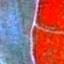

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: guaxupe.T3520.B3584.L3392.R3456
Is coffee: coffee
Model predicted: coffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold2/guaxupe.T3520.B3584.L3392.R3456.jpg


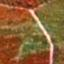

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Image: guaranesia.T1216.B1280.L3392.R3456
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold3/guaranesia.T1216.B1280.L3392.R3456.jpg


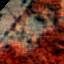

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Image: guaranesia.T5312.B5376.L3136.R3200
Is coffee: coffee
Model predicted: coffee
Confidence: 81.9000015258789%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold3/guaranesia.T5312.B5376.L3136.R3200.jpg


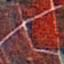

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Image: guaranesia.T3008.B3072.L6528.R6592
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 100.0%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/guaranesia.T3008.B3072.L6528.R6592.jpg


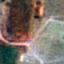

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Image: montesanto.T8064.B8128.L10880.R10944
Is coffee: noncoffee
Model predicted: noncoffee
Confidence: 99.98999786376953%
/Users/simenkrogstie/Documents/Programming/H26/GMFM350/notebooks/exercise_6/data/fold1/montesanto.T8064.B8128.L10880.R10944.jpg


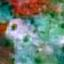

'\npredict_coffee_crop_show_results(20)\npredict_coffee_crop_show_results(90)\npredict_coffee_crop_show_results(101)\npredict_coffee_crop_show_results(201)\npredict_coffee_crop_show_results(301)\npredict_coffee_crop_show_results(401)\npredict_coffee_crop_show_results(501)\npredict_coffee_crop_show_results(601)\n'

In [25]:
import os

def find_file_in_subfolder(root, filename):
    # returns a full path to file from the root
    for file_root, dirs, files in os.walk(root):
        for name in files:
            if name == filename:
                return file_root + '/' + name


def predict_coffee_crop_show_results(img_nr):
    prediction = model.predict(test_ds_photos[img_nr].reshape(-1, 64, 64, 3))[0][0]
    
    image_name = test_ds[img_nr][1]
    image_status = test_ds[img_nr][0]

    print(f'Image: {image_name}')
    print(f'Is coffee: {image_status}')
    if prediction > 0.5: 
        print('Model predicted: coffee')
        print(f'Confidence: {round(prediction * 100, 2)}%')
    else:
        print('Model predicted: noncoffee')
        print(f'Confidence: {round((1 - prediction) * 100, 2)}%')

    #img_path = find_file_in_subfolder('/kaggle/input/barazilian-coffee-scenes/', image_name + '.jpg')
    img_path = find_file_in_subfolder(str(DATA_PATH), image_name + '.jpg')
    print(img_path)
    img = Image.open(img_path)

    display(img)
    
for k in range(20):
    ind=random.randrange(len(test_ds))
    predict_coffee_crop_show_results(ind)
"""
predict_coffee_crop_show_results(20)
predict_coffee_crop_show_results(90)
predict_coffee_crop_show_results(101)
predict_coffee_crop_show_results(201)
predict_coffee_crop_show_results(301)
predict_coffee_crop_show_results(401)
predict_coffee_crop_show_results(501)
predict_coffee_crop_show_results(601)
"""